# Tutorial 3 — MNIST ANN and controlled experiments

Build the 784–128–64–10 classifier, compare activations, architectures and optimizers, then demonstrate dropout, L2 and early stopping.

**How to run:** select a Python kernel with the repository requirements, then Run All. QUICK mode keeps experiments short. For the larger run set `TUTORIAL_FULL=1` before starting the kernel. A quick run demonstrates the method; it is not a final accuracy benchmark.

In [1]:
# Google Colab: fetch the support files and install missing dependencies.
# Local Jupyter: follow README setup once; this cell makes no changes.
import sys, subprocess
from pathlib import Path
if "google.colab" in sys.modules:
    repo = Path("/content/dl-course-tutorials")
    if not repo.exists():
        subprocess.check_call(["git", "clone", "https://github.com/naveed952/Tutorial-01_Perceptron_py.ipynb.git", str(repo)])
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "-r", str(repo/"requirements.txt")])
    import os
    os.chdir(repo)


## Step 1 — Locate the project and set a reproducible seed
A fixed seed makes comparisons easier to reproduce. Each notebook can run independently.

In [2]:
from pathlib import Path
import sys, os
ROOT = Path.cwd() if (Path.cwd()/"tutorial_support").exists() else Path.cwd().parent
assert (ROOT/"tutorial_support").exists(), "Run from the repository or notebooks folder."
sys.path.insert(0, str(ROOT))
from tutorial_support.common import *
seed()
print("Mode:", "QUICK: small real-data run" if QUICK else "FULL: larger training run")

Mode: QUICK: small real-data run


## Step 2 — Load MNIST and reserve validation examples
Divide pixels by 255; convert class IDs to one-hot vectors. QUICK uses a subset of real MNIST, not random labels. The test set is used only after model selection.

In [3]:
keras=keras_setup()
from sklearn.model_selection import train_test_split
import pandas as pd, time
import matplotlib.pyplot as plt
(x,y),(xt,yt)=keras.datasets.mnist.load_data()
if QUICK:x,y=x[:6000],y[:6000];xt,yt=xt[:1000],yt[:1000]
xtr,xv,ytr,yv=train_test_split(x/255.,y,test_size=.2,stratify=y,random_state=SEED)
xt=xt/255.;ytr=keras.utils.to_categorical(ytr,10);yv=keras.utils.to_categorical(yv,10)
print(xtr.shape,ytr.shape);print('Digit 3 one-hot:',keras.utils.to_categorical(3,10))

       0/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0s/step

   16384/11490434 ━━━━━━━━━━━━━━━━━━━━ 1:51 10us/step

   32768/11490434 ━━━━━━━━━━━━━━━━━━━━ 1:19 7us/step 

   49152/11490434 ━━━━━━━━━━━━━━━━━━━━ 1:27 8us/step

   73728/11490434 ━━━━━━━━━━━━━━━━━━━━ 1:06 6us/step

   81920/11490434 ━━━━━━━━━━━━━━━━━━━━ 1:22 7us/step

... (128 outputs left out)

11313152/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 1us/step

11411456/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 1us/step

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 10s 1us/step


(4800, 28, 28) (4800, 10)
Digit 3 one-hot: [0. 0. 0. 1. 0. 0. 0. 0. 0. 0.]


## Step 3 — Define a configurable network
Flatten has no learned parameters. Each Dense layer computes weighted sums and an activation. Softmax produces 10 probabilities. Regularization changes the objective; dropout is disabled at evaluation.

In [4]:
def build_ann(widths=(128,64),activation='relu',optimizer='adam',regularized=False):
    keras.utils.set_random_seed(SEED)
    layers=[keras.layers.Input((28,28)),keras.layers.Flatten()]
    for width in widths:
        layers.append(keras.layers.Dense(width,activation=activation,kernel_regularizer=keras.regularizers.l2(1e-4) if regularized else None))
        if regularized:layers.append(keras.layers.Dropout(.2))
    layers.append(keras.layers.Dense(10,activation='softmax'))
    model=keras.Sequential(layers)
    model.compile(optimizer=optimizer,loss='categorical_crossentropy',metrics=['accuracy'])
    return model
base=build_ann();base.summary();assert base.count_params()==109386

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 109,386 (427.29 KB)

 Trainable params: 109,386 (427.29 KB)

 Non-trainable params: 0 (0.00 B)

## Step 4 — Run all assigned comparisons
The variants isolate changes relative to the baseline. Compare validation accuracy, time and learning curves. Early stopping restores weights from the best validation-loss epoch.

,model,val_loss,val_accuracy,seconds,epochs
3,tanh,0.240376,0.932500,2.319833,3
0,baseline,0.240619,0.927500,2.700524,3
6,RMSprop,0.251703,0.930833,2.244749,3
2,deep,0.265062,0.925833,2.654889,3
7,regularized,0.288252,0.927500,3.911595,3
1,small,0.328820,0.914167,2.058586,3
4,sigmoid,0.402631,0.907500,2.338068,3
5,SGD,0.654873,0.848333,2.113457,3


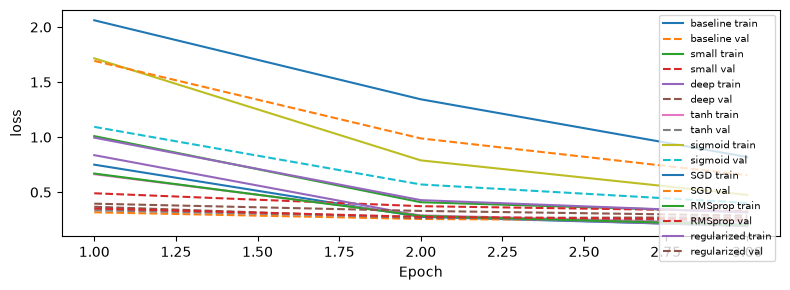

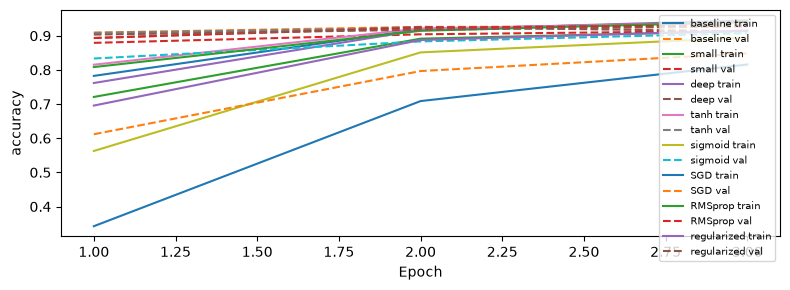

Selected: tanh held-out test loss/accuracy: [0.29363805055618286, 0.9079999923706055]


WindowsPath('D:/Disk E/Robotics And Ai/Deep  Learning/completed-tutorials/artifacts/03_ann.json')

In [5]:
configs=[('baseline',{}),('small',{'widths':(32,)}),('deep',{'widths':(128,64,32)}),('tanh',{'activation':'tanh'}),('sigmoid',{'activation':'sigmoid'}),('SGD',{'optimizer':'sgd'}),('RMSprop',{'optimizer':'rmsprop'}),('regularized',{'regularized':True})]
histories={};models={};rows=[]
for name,kw in configs:
    model=build_ann(**kw);start=time.perf_counter()
    callbacks=[keras.callbacks.EarlyStopping(monitor='val_loss',patience=2,restore_best_weights=True)]
    h=model.fit(xtr,ytr,validation_data=(xv,yv),epochs=3 if QUICK else 15,batch_size=32,verbose=0,callbacks=callbacks)
    histories[name]=h;models[name]=model
    val=model.evaluate(xv,yv,verbose=0)
    rows.append({'model':name,'val_loss':val[0],'val_accuracy':val[1],'seconds':time.perf_counter()-start,'epochs':len(h.history['loss'])})
results=pd.DataFrame(rows).sort_values('val_loss');display(results)
curves(histories);curves(histories,'accuracy')
chosen=results.iloc[0]['model'];test=models[chosen].evaluate(xt,keras.utils.to_categorical(yt,10),verbose=0)
print('Selected:',chosen,'held-out test loss/accuracy:',test)
save_result('03_ann',{'comparison':rows,'selected':chosen,'test':test})

## Step 5 — Inspect actual predictions and cross-entropy
The loss for a one-hot target is minus the log of the probability assigned to the correct digit. A prediction can be correct but still have nonzero loss.

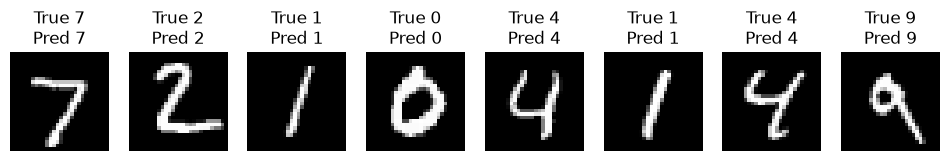

Example CE: 0.005935307


In [6]:
prob=models[chosen].predict(xt[:8],verbose=0)
fig,axes=plt.subplots(1,8,figsize=(12,2))
for i,ax in enumerate(axes):ax.imshow(xt[i],cmap='gray');ax.set_title(f'True {yt[i]}\nPred {prob[i].argmax()}');ax.axis('off')
plt.show();print('Example CE:',-np.log(np.clip(prob[0,yt[0]],1e-8,1)))

## Task conclusions
Low training and validation accuracy suggests underfitting; high training but weaker validation accuracy suggests overfitting. A short quick run may not show overfitting yet. Compare the measured curves rather than claiming that regularization always wins. Longer training, a larger model and a smaller training subset can make overfitting more visible.

## Explain it in class
Describe the input, target, model, loss, update rule and evaluation split. Use the displayed results from your own run. Changing the dataset, seed or training budget can change the result.

**Course source:** the matching tutorial PDF supplied in the Deep Learning course. Original explanatory implementation; the course PDFs are not redistributed.

## Task answers and revision check

**Recorded quick-run comparison:** tanh had the lowest validation loss (0.24038), narrowly ahead of the ReLU baseline (0.24062). The tanh model's validation accuracy was 93.25%; held-out test accuracy was 90.80% on 1,000 examples. Training used 4,800 examples and validation used 1,200, for three epochs per variant.

**Does that prove tanh is better than ReLU?** No. The loss difference is tiny, the dataset subset is small and there is only one seed. The result supports this run's selection, not a universal activation ranking.

**Did regularization win?** Its validation accuracy matched the baseline at 92.75%, but its recorded total validation loss was larger. L2 adds a penalty to the loss, so regularized total loss is not exactly the same quantity as unregularized data loss. Consider accuracy and data-only loss as well.

**Did early stopping stop training early?** All recorded variants completed the three-epoch quick budget. The callback is implemented, but this run does not demonstrate an early stop. A longer run is needed to observe that behavior.

**Parameter numerical:** 784→128 has 784×128 weights + 128 biases = 100,480. Flatten has zero trainable parameters. The complete baseline has 109,386 parameters.

**Oral question:** why not add softmax before PyTorch CrossEntropyLoss? It expects raw logits and combines log-softmax with the loss internally. In this Keras model, probabilities and the probability-form loss are paired explicitly.
